In [ ]:
import sys
sys.path.insert(0, '..')

import warnings
from itertools import combinations, permutations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, optimize

from tcr_pipeline.normalization import tmm_normalize
from tcr_pipeline.data_io import sample_qc, drop_failed_samples
from tcr_pipeline import nb_glm_old as nb

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 160)

CUTOFF_FRAC = 1e-6           # upstream filter: frequency >= 1e-6 of in-frame reads

# plotting: one fixed colour per donor (same colour in every figure), recessive axes
DONOR_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
GREY = '#8a8984'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#3d3c39', 'xtick.color': '#52514e',
    'ytick.color': '#52514e', 'lines.linewidth': 1.6, 'lines.markersize': 5,
    'legend.frameon': False, 'font.size': 9.5, 'axes.titlesize': 10})

In [ ]:
healthy_raw = pd.read_csv('../data/healthy_raw.csv', index_col=0)
patients_raw = pd.read_csv('../data/patients_raw.csv', index_col=0)

DONORS = sorted(healthy_raw['patient'].unique())
COLOR = dict(zip(DONORS, DONOR_COLORS))
short = lambda p: p.replace('_SEQTR', '').replace('_ReSeq', '')
print(len(healthy_raw), 'donor rows;', len(patients_raw), 'patient rows')
healthy_raw.head()

2969992 donor rows; 3193746 patient rows


,patient,day,clono,count,freq_in,D_t,c_t,lib_post
0,HD106_SEQTR,0,clono_1,226089,1.088219,20776057.0,21.0,19064838
1,HD106_SEQTR,0,clono_2,159926,0.769761,20776057.0,21.0,19064838
2,HD106_SEQTR,0,clono_3,141200,0.679628,20776057.0,21.0,19064838
3,HD106_SEQTR,0,clono_4,82582,0.397486,20776057.0,21.0,19064838
4,HD106_SEQTR,0,clono_5,70402,0.338861,20776057.0,21.0,19064838


In [ ]:
g = healthy_raw.groupby(["patient", "day"])
samples_h =g.agg(D_t=('D_t', 'first'), lib_post=('lib_post', 'first'), c_t=('c_t', 'first'),
              n_clones=('clono', 'size'), top_clone_share=('freq_in', 'max'))
samples_h['top_clone_share'] = samples_h['top_clone_share'] / 100

Lets examine the composition of the data. In the table below, we summarize the number of samples per patient and their respective days, the maximum and minimum sequency depth (in millions of coutns), maximum and minimum number of clones detected (in thousands) and the % share of the top clone.

In [ ]:
g = healthy_raw.groupby(["patient", "day"])
samples_h =g.agg(D_t=('D_t', 'first'), lib_post=('lib_post', 'first'), c_t=('c_t', 'first'),
              n_clones=('clono', 'size'), top_clone_share=('freq_in', 'max'))
samples_h['top_clone_share'] = samples_h['top_clone_share'] / 100

In [ ]:
per_donor = samples_h.groupby('patient').agg(
    n_samples=('D_t', 'size'),
    days=('D_t', lambda s: ', '.join(map(str, s.index.get_level_values('day')))),
    depth_M=('D_t', lambda s: f"{s.min()/1e6:.1f}–{s.max()/1e6:.1f}"),
    clones_k=('n_clones', lambda s: f"{s.min()/1e3:.1f}–{s.max()/1e3:.0f}"),
    top_clone=('top_clone_share', lambda s: f"{s.min():.3f}–{s.max():.3f}"))
display(per_donor)

,n_samples,days,depth_M,clones_k,top_clone
patient,,,,,
HD106_SEQTR,4,"0, 46, 82, 131",13.2–20.8,166.7–214,0.009–0.012
HD197_SEQTR,4,"0, 46, 82, 131",15.1–17.7,179.5–213,0.006–0.011
HDBR01_SEQTR_ReSeq,4,"0, 21, 42, 126",10.2–21.3,101.8–133,0.003–0.003
HDBR02_SEQTR_ReSeq,3,"0, 48, 71",5.4–8.9,53.3–94,0.156–0.259
HDBR03_SEQTR_ReSeq,5,"0, 21, 35, 66, 84",4.9–10.7,71.6–157,0.017–0.041
HDBR06_SEQTR_ReSeq,4,"0, 21, 82, 105",5.1–11.5,0.7–85,0.036–0.242


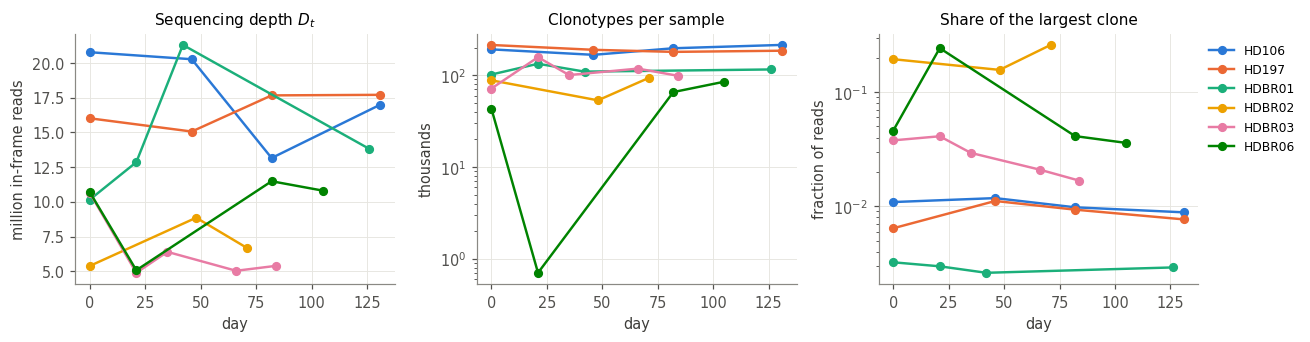

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for p in DONORS:
    s = samples_h.loc[p]
    kw = dict(color=COLOR[p], marker='o', label=short(p))
    axes[0].plot(s.index, s['D_t'] / 1e6, **kw)
    axes[1].plot(s.index, s['n_clones'] / 1e3, **kw)
    axes[2].plot(s.index, s['top_clone_share'], **kw)
axes[0].set(title='Sequencing depth $D_t$', xlabel='day', ylabel='million in-frame reads')
axes[1].set(title='Clonotypes per sample', xlabel='day', ylabel='thousands', yscale='log')
axes[2].set(title='Share of the largest clone', xlabel='day', ylabel='fraction of reads',
            yscale='log')
axes[2].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.tight_layout()

From this table and figures, we can notice several features worth mentioning:

* Depth varies about 4-fold across samples (4.9–21.3 M reads), within as well as between donors. A clone's read count is only comparable across samples after dividing by depth, so every model below uses an offset factor.
* Donors differ far more in repertoire structure than in depth: from about 43 k to 214 k clonotypes per sample (one failed sample aside), and a largest clone holding from 0.3 % (HDBR01) to 26 % (HDBR02) of reads. Any per-sample quality criterion therefore has to be relative to the same person.
* One sample is obviously different from everything else: HDBR06 day 21, with 706 clonotypes against 43–85 k in the donor's other samples